# Medical Waste Data Cleaning and Preprocessing

Issue #3 — MED-WASTE-SEGREGATION (Data Analytics & Visualization)

**Input:** `data/raw/medical_waste.csv` — 1,500 simulated waste-segregation records (October 2026), 12 columns.
**Output:** `data/processed/medical_waste_cleaned.csv`

The raw file is never changed. All cleaning logic lives in `src/preprocessing.py`; this notebook calls it, shows what it does at each step, and validates the result. Every cell-level change is kept in an audit table.

**Cleaning rules in short**

| Problem | Decision |
|---|---|
| Spelling, case, spacing and alias variants | Mapped to one standard label |
| Values that cannot be mapped safely (`Other`, `Purple Bin`, `BIN_99`, `Floor 9` ...) | Set to missing, not guessed |
| Text in numeric columns (`1,250`, `85%`, `full`) | Converted to numbers; `unknown`, `N/A` become missing |
| Impossible numbers (negative weight, confidence above 1, fill above 100 %) | Set to missing |
| Mixed timestamp formats | Converted; ambiguous `07/10/2026` resolved with the October 2026 window; impossible dates become missing |
| Rows identical except for `Record_ID` | Removed (first occurrence kept), listed in the audit |
| Reused `Record_ID` with different content | Kept and flagged (`Duplicate_Record_ID`); `Row_Number` is the unique key |
| Statistical outliers (IQR) | Flagged, not removed |
| Missing values | Kept as missing, no imputation |

## 0. Setup

In [1]:
from pathlib import Path
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocessing import (
    RAW_PATH, CLEAN_PATH, CATEGORICAL_COLUMNS, load_raw, clean_dataframe,
    validate_dataframe, missing_value_report, iqr_outlier_summary,
    encode_and_scale, save_cleaned,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

RAW_HASH_BEFORE = sha256(RAW_PATH)
print("Raw file:", RAW_PATH.relative_to(ROOT))
print("SHA-256 before cleaning:", RAW_HASH_BEFORE)

Raw file: data/raw/medical_waste.csv
SHA-256 before cleaning: d58a0c4ef79bdd989b1f8abb11985a124624c4d4a393d3337258b70a725fd579


## 1. Load and inspect the raw data

Everything is read as text first, so nothing is converted or lost on the way in.

In [2]:
raw_df = load_raw(RAW_PATH)
print("Shape:", raw_df.shape)
display(raw_df.head(8))

Shape: (1500, 12)


,Record_ID,Timestamp,Hospital_Ward,Floor_Number,Waste_Category,Target_Bin_Color,Bin_ID,Weight_Grams,AI_Confidence_Score,Segregation_Status,Bin_Fill_Level_Percentage,Alert_Triggered
0,REC0001,2026-10-07 08:24:00,Emergency,Floor 4,Surgical Waste,Yellow Bin,BIN_02,283.5,0.87,Correctly Segregated,33.0,No
1,REC0002,2026-10-28 09:33:00,ICU,Floor 4,Used Bandages,Yellow Bin,BIN_04,170.6,0.91,Correctly Segregated,69.0,No
2,REC0003,2026-10-01 07:05:00,OT,Floor 3,Expired Medications,White Bin,BIN_06,319.9,0.78,Correctly Segregated,40.0,No
3,REC0004,2026-10-18 06:58:00,Emergency,Floor 2,Urine/Body Fluids,Red Bin,BIN_06,644.5,0.88,Misclassified,16.0,Yes
4,REC0005,2026-10-04 14:04:00,Pediatrics,Floor 4,Used Bandages,Yellow Bin,BIN_06,,0.87,Correctly Segregated,53.0,No
5,REC0006,2026-10-04 15:09:00,OPD,Ground,,Yellow Bin,BIN_07,158.0,0.78,Correctly Segregated,42.0,No
6,REC0007,2026-10-13 03:36:00,Emergency,Floor 4,Paper Wrappers,Black Bin,BIN_11,674.1,0.75,Correctly Segregated,90.0,Yes
7,REC0008,2026-10-26 08:20:00,OPD,Floor 2,Glassware,Blue Bin,BIN_01,352.1,0.77,Correctly Segregated,86.0,Yes


In [3]:
print("Distinct raw values per column:")
display(raw_df.nunique().rename("distinct_raw_values").to_frame())

Distinct raw values per column:


,distinct_raw_values
Record_ID,1489
Timestamp,1458
Hospital_Ward,29
Floor_Number,13
Waste_Category,40
Target_Bin_Color,14
Bin_ID,25
Weight_Grams,1277
AI_Confidence_Score,36
Segregation_Status,7


## 2. Missing values

In [4]:
blank = (raw_df.apply(lambda s: s.str.strip()) == "").sum()
placeholders = {"nan", "none", "null", "unknown", "n/a", "na", "not recorded"}
placeholder = raw_df.apply(lambda s: s.str.strip().str.lower().isin(placeholders)).sum()
miss = pd.DataFrame({"blank_cells": blank, "placeholder_text": placeholder})
miss["total"] = miss.sum(axis=1)
display(miss)
print("Total blank cells:", int(blank.sum()), "| placeholder-text cells:", int(placeholder.sum()))

,blank_cells,placeholder_text,total
Record_ID,0,0,0
Timestamp,0,1,1
Hospital_Ward,36,2,38
Floor_Number,26,0,26
Waste_Category,18,0,18
Target_Bin_Color,0,0,0
Bin_ID,22,0,22
Weight_Grams,27,1,28
AI_Confidence_Score,19,1,20
Segregation_Status,18,0,18


Total blank cells: 201 | placeholder-text cells: 5


Blank cells appear in 9 of the 12 columns (about 1 to 2.5 % each). `Record_ID`, `Timestamp` and `Target_Bin_Color` have no blanks. Placeholder text such as `Unknown`, `nan`, `N/A` and `not recorded` is treated as missing as well.

Missing values are **not imputed**: no safe rule exists to guess a ward, weight or confidence score, and the share is small enough for analyses to simply skip them.

## 3. Duplicate records

In [5]:
ids = raw_df["Record_ID"].str.strip()
print("Fully identical rows (as received):", int(raw_df.duplicated().sum()))
print("Rows with a Record_ID that appears more than once:", int(ids.duplicated(keep=False).sum()),
      f"({int((ids.value_counts() > 1).sum())} IDs)")

# Rows identical in every field except Record_ID (after trimming and lower-casing)
norm = raw_df.drop(columns="Record_ID").apply(lambda s: s.str.strip().str.lower())
copies = norm.duplicated(keep=False)
print("Rows identical to another row except for Record_ID:", int(copies.sum()), f"({int(copies.sum() / 2)} pairs)")
example = raw_df[copies].assign(_key=norm[copies].astype(str).agg("|".join, axis=1)).sort_values("_key").drop(columns="_key")
display(example.head(6))

Fully identical rows (as received): 0
Rows with a Record_ID that appears more than once: 22 (11 IDs)
Rows identical to another row except for Record_ID: 36 (18 pairs)


,Record_ID,Timestamp,Hospital_Ward,Floor_Number,Waste_Category,Target_Bin_Color,Bin_ID,Weight_Grams,AI_Confidence_Score,Segregation_Status,Bin_Fill_Level_Percentage,Alert_Triggered
569,REC0570,2026-10-03 17:35:00,icu,Floor 2,Syringes,Green Bin,BIN_11,143.9,0.74,Correctly Segregated,85.0,No
427,REC0428,2026-10-03 17:35:00,icu,Floor 2,Syringes,Green Bin,BIN_11,143.9,0.74,Correctly Segregated,85.0,No
4,REC0005,2026-10-04 14:04:00,Pediatrics,Floor 4,Used Bandages,Yellow Bin,BIN_06,,0.87,Correctly Segregated,53.0,No
1066,REC1067,2026-10-04 14:04:00,Pediatrics,Floor 4,Used Bandages,Yellow Bin,BIN_06,,0.87,Correctly Segregated,53.0,No
744,REC0745,2026-10-07 10:16:00,Radiology,Floor 1,Hazardous Chemicals,White Bin,BIN_12,460.7,0.81,Correctly Segregated,40.0,No
715,REC0716,2026-10-07 10:16:00,Radiology,Floor 1,Hazardous Chemicals,White Bin,BIN_12,460.7,0.81,Correctly Segregated,40.0,No


Two different duplicate problems exist:

1. **Copies with a new ID.** 18 pairs of rows match in every other field, down to the minute, ward, weight and bin. These are the same record entered twice, so the second occurrence is removed.
2. **Reused `Record_ID`.** 11 IDs are used by two rows that have different content. They are different events, so both rows are kept and flagged. The IDs do not follow the row order cleanly enough to repair them without guessing, so `Row_Number` (the line number in the raw CSV) serves as the unique key.

## 4. Clean the data

`clean_dataframe` returns the cleaned table, a cell-level audit and the removed duplicate rows.

In [6]:
cleaned_df, audit_df, removed_df = clean_dataframe(raw_df)
print("Raw rows:", len(raw_df), "| cleaned rows:", len(cleaned_df), "| removed copies:", len(removed_df))
print("Audit entries (changed cells and removed rows):", len(audit_df))
display(cleaned_df.head(8))

Raw rows: 1500 | cleaned rows: 1482 | removed copies: 18
Audit entries (changed cells and removed rows): 1154


,Row_Number,Record_ID,Timestamp,Hospital_Ward,Floor_Number,Waste_Category,Target_Bin_Color,Bin_ID,Weight_Grams,AI_Confidence_Score,Segregation_Status,Bin_Fill_Level_Percentage,Alert_Triggered,Duplicate_Record_ID,Date,Hour,Weekday,Category_Bin_Mismatch,Weight_Outlier
0,2,REC0001,2026-10-07 08:24:00,Emergency,Floor 4,Surgical Waste,Yellow Bin,BIN_02,283.5,0.87,Correctly Segregated,33.0,No,False,2026-10-07,8,Wednesday,False,False
1,3,REC0002,2026-10-28 09:33:00,ICU,Floor 4,Used Bandages,Yellow Bin,BIN_04,170.6,0.91,Correctly Segregated,69.0,No,False,2026-10-28,9,Wednesday,False,False
2,4,REC0003,2026-10-01 07:05:00,OT,Floor 3,Expired Medications,White Bin,BIN_06,319.9,0.78,Correctly Segregated,40.0,No,False,2026-10-01,7,Thursday,False,False
3,5,REC0004,2026-10-18 06:58:00,Emergency,Floor 2,Urine/Body Fluids,Red Bin,BIN_06,644.5,0.88,Misclassified,16.0,Yes,False,2026-10-18,6,Sunday,False,False
4,6,REC0005,2026-10-04 14:04:00,Pediatrics,Floor 4,Used Bandages,Yellow Bin,BIN_06,NaN,0.87,Correctly Segregated,53.0,No,False,2026-10-04,14,Sunday,False,False
5,7,REC0006,2026-10-04 15:09:00,OPD,Ground,NaN,Yellow Bin,BIN_07,158.0,0.78,Correctly Segregated,42.0,No,False,2026-10-04,15,Sunday,False,False
6,8,REC0007,2026-10-13 03:36:00,Emergency,Floor 4,Paper Wrappers,Black Bin,BIN_11,674.1,0.75,Correctly Segregated,90.0,Yes,False,2026-10-13,3,Tuesday,False,True
7,9,REC0008,2026-10-26 08:20:00,OPD,Floor 2,Glassware,Blue Bin,BIN_01,352.1,0.77,Correctly Segregated,86.0,Yes,False,2026-10-26,8,Monday,False,False


In [7]:
summary = (audit_df.assign(decision=audit_df["decision"].str.replace(r"^Standardised .*", "Standardised label (case, spacing, spelling, alias)", regex=True))
           .groupby(["column", "decision"]).size().rename("cells").reset_index())
display(summary)

,column,decision,cells
0,(whole row),Row removed: identical to an earlier row in ev...,18
1,AI_Confidence_Score,Impossible confidence value; set to missing,3
2,AI_Confidence_Score,Placeholder text treated as missing,1
3,Alert_Triggered,Not a valid alert flag (Yes/No); set to missin...,2
4,Alert_Triggered,"Standardised label (case, spacing, spelling, a...",180
5,Bin_Fill_Level_Percentage,'full' converted to 100.0,1
6,Bin_Fill_Level_Percentage,Impossible fill level value; set to missing,3
7,Bin_ID,Not a valid bin ID (BIN_01 to BIN_12); set to ...,1
8,Bin_ID,"Standardised label (case, spacing, spelling, a...",26
9,Floor_Number,Not a valid floor; set to missing (not guessed),2


## 5. Inconsistent labels: before and after

In [8]:
for col in CATEGORICAL_COLUMNS:
    after = cleaned_df[col].nunique(dropna=True)
    print(f"{col:20s} distinct raw values: {raw_df[col].nunique():3d}  ->  {after:2d} standard values")

Hospital_Ward        distinct raw values:  29  ->   8 standard values
Floor_Number         distinct raw values:  13  ->   5 standard values
Waste_Category       distinct raw values:  40  ->  19 standard values
Target_Bin_Color     distinct raw values:  14  ->   6 standard values
Bin_ID               distinct raw values:  25  ->  12 standard values
Segregation_Status   distinct raw values:   7  ->   2 standard values
Alert_Triggered      distinct raw values:   7  ->   2 standard values


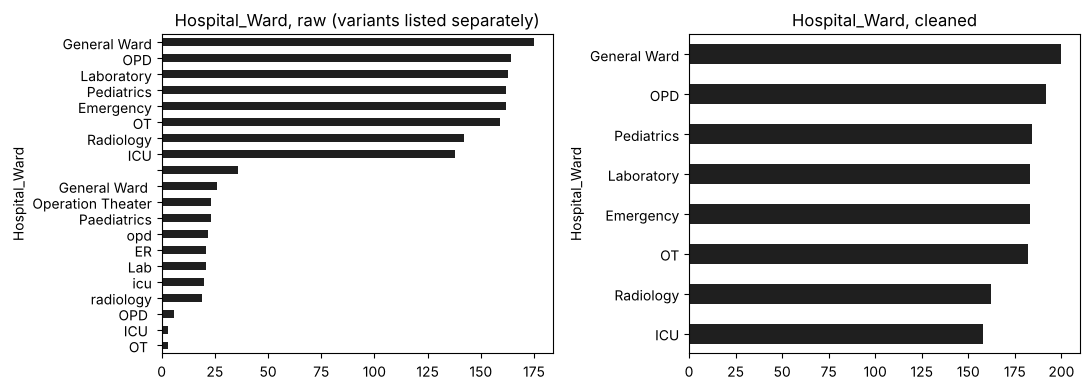

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw_df["Hospital_Ward"].value_counts().head(20).sort_values().plot.barh(ax=axes[0], color="#1f1f1f")
axes[0].set_title("Hospital_Ward, raw (variants listed separately)")
cleaned_df["Hospital_Ward"].value_counts().sort_values().plot.barh(ax=axes[1], color="#1f1f1f")
axes[1].set_title("Hospital_Ward, cleaned")
plt.tight_layout(); plt.show()

## 6. Invalid records and data types

In [10]:
invalid = audit_df[audit_df["decision"].str.contains("Impossible|Not a valid|Not a usable|Ambiguous|Converted|converted|Placeholder|Removed thousands", regex=True)]
display(invalid[["row_number", "record_id", "column", "original_value", "cleaned_value", "decision"]].sort_values(["column", "row_number"]).reset_index(drop=True))

,row_number,record_id,column,original_value,cleaned_value,decision
0,99,REC0098,AI_Confidence_Score,1.4,None,Impossible confidence value; set to missing
1,220,REC0219,AI_Confidence_Score,2.5,None,Impossible confidence value; set to missing
2,294,REC0293,AI_Confidence_Score,N/A,None,Placeholder text treated as missing
3,715,REC0714,AI_Confidence_Score,-0.2,None,Impossible confidence value; set to missing
4,206,REC0205,Alert_Triggered,1,None,Not a valid alert flag (Yes/No); set to missin...
5,821,REC0820,Alert_Triggered,Maybe,None,Not a valid alert flag (Yes/No); set to missin...
6,504,REC0503,Bin_Fill_Level_Percentage,-10.0,None,Impossible fill level value; set to missing
7,713,REC0712,Bin_Fill_Level_Percentage,full,100.0,'full' converted to 100.0
8,1180,REC1179,Bin_Fill_Level_Percentage,180.0,None,Impossible fill level value; set to missing
9,1297,REC1296,Bin_Fill_Level_Percentage,125.0,None,Impossible fill level value; set to missing


In [11]:
display(cleaned_df.dtypes.rename("dtype").to_frame())

,dtype
Row_Number,int64
Record_ID,str
Timestamp,datetime64[ns]
Hospital_Ward,object
Floor_Number,object
Waste_Category,object
Target_Bin_Color,object
Bin_ID,object
Weight_Grams,float64
AI_Confidence_Score,float64


## 7. Outliers

Impossible values were already set to missing in step 4 (for example weights of 250,000 and 999,999 g, confidence of 2.5, fill level of 180 %). What remains is checked with the 1.5 × IQR rule. Outliers are **flagged** (`Weight_Outlier`), not removed, because large items in a hospital are plausible.

,column,lower_fence,upper_fence,flagged_count,min_flagged,max_flagged
0,Weight_Grams,-210.600,659.800,105,664.6,4155.5
1,AI_Confidence_Score,0.545,1.145,0,NaN,NaN
2,Bin_Fill_Level_Percentage,-47.000,153.000,0,NaN,NaN


Weights flagged as outliers: 105 of 1451


/tmp/ipykernel_163/3889630348.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(cleaned_df["Weight_Grams"].dropna(), vert=False, flierprops={"markerfacecolor": "#d62728", "markersize": 3})


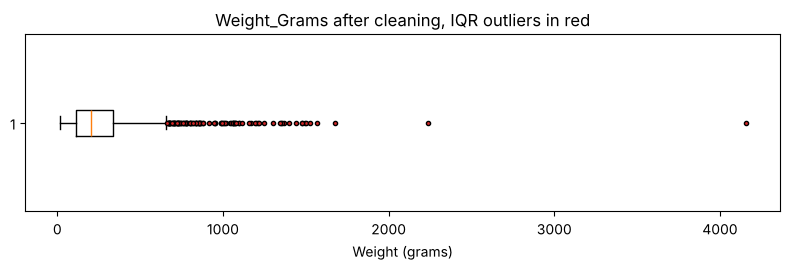

In [12]:
display(iqr_outlier_summary(cleaned_df))
print("Weights flagged as outliers:", int(cleaned_df["Weight_Outlier"].sum()), "of", int(cleaned_df["Weight_Grams"].notna().sum()))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.boxplot(cleaned_df["Weight_Grams"].dropna(), vert=False, flierprops={"markerfacecolor": "#d62728", "markersize": 3})
ax.set_xlabel("Weight (grams)"); ax.set_title("Weight_Grams after cleaning, IQR outliers in red")
plt.tight_layout(); plt.show()

The weight distribution is right-skewed (median about 200 g, a long tail up to 4,155.5 g), so the IQR rule flags the heavy tail. AI confidence and bin fill level have no outliers once impossible values are removed.

## 8. Consistency check: waste category vs bin colour

In [13]:
print("Records whose bin colour differs from the usual colour for their category:", int(cleaned_df["Category_Bin_Mismatch"].sum()))
display(pd.crosstab(cleaned_df["Category_Bin_Mismatch"], cleaned_df["Segregation_Status"], margins=True))

Records whose bin colour differs from the usual colour for their category: 88


Segregation_Status,Correctly Segregated,Misclassified,All
Category_Bin_Mismatch,,,
False,1281,94,1375
True,84,4,88
All,1365,98,1463


These records are flagged in `Category_Bin_Mismatch`, not changed. The usual colour is taken from the data (most common colour per category), not from an external regulation.

## 9. Encoding and scaling

Not applied to the cleaned CSV. The planned analytics and charts need real units (grams, percent) and readable labels, and scaling would only hurt them. For any later modelling step, `encode_and_scale` returns a one-hot encoded, min-max scaled copy:

In [14]:
model_ready = encode_and_scale(cleaned_df)
print("Modelling-ready copy (not saved):", model_ready.shape)
display(model_ready.iloc[:3, :8])

Modelling-ready copy (not saved): (1482, 57)


,Weight_Grams,AI_Confidence_Score,Bin_Fill_Level_Percentage,Hospital_Ward_Emergency,Hospital_Ward_General Ward,Hospital_Ward_ICU,Hospital_Ward_Laboratory,Hospital_Ward_OPD
0,0.065005,0.586207,0.33,1,0,0,0,0
1,0.037743,0.724138,0.69,0,0,1,0,0
2,0.073795,0.275862,0.40,0,0,0,0,0


## 10. Validate and save

In [15]:
checks = validate_dataframe(cleaned_df, raw_df, removed_df)
display(checks)
assert checks["passed"].all(), "A validation check failed"
print(f"All {len(checks)} validation checks passed")

,check,passed,details
0,every raw row accounted for,True,1500 raw = 1482 kept + 18 removed copies
1,12 raw columns kept,True,all present
2,Row_Number is unique,True,unique=1482
3,no rows identical except for Record_ID,True,remaining=0
4,Timestamp is datetime,True,dtype=datetime64[ns]
5,timestamps inside 1-30 Oct 2026,True,"min=2026-10-01 01:23:00, max=2026-10-30 23:58:00"
6,Hospital_Ward uses only standard values,True,8 distinct values
7,Floor_Number uses only standard values,True,5 distinct values
8,Waste_Category uses only standard values,True,19 distinct values
9,Target_Bin_Color uses only standard values,True,6 distinct values


All 19 validation checks passed


In [16]:
display(missing_value_report(cleaned_df))

,missing,missing_pct
Record_ID,0,0.00
Timestamp,2,0.13
Hospital_Ward,38,2.56
Floor_Number,27,1.82
Waste_Category,20,1.35
Target_Bin_Color,1,0.07
Bin_ID,23,1.55
Weight_Grams,31,2.09
AI_Confidence_Score,22,1.48
Segregation_Status,19,1.28


In [17]:
path = save_cleaned(cleaned_df)
reloaded = pd.read_csv(path)
print("Saved:", Path(path).relative_to(ROOT), "| shape:", reloaded.shape)
print("Raw file unchanged:", sha256(RAW_PATH) == RAW_HASH_BEFORE)
assert sha256(RAW_PATH) == RAW_HASH_BEFORE
display(reloaded.head(5))

Saved: data/processed/medical_waste_cleaned.csv | shape: (1482, 19)
Raw file unchanged: True


,Row_Number,Record_ID,Timestamp,Hospital_Ward,Floor_Number,Waste_Category,Target_Bin_Color,Bin_ID,Weight_Grams,AI_Confidence_Score,Segregation_Status,Bin_Fill_Level_Percentage,Alert_Triggered,Duplicate_Record_ID,Date,Hour,Weekday,Category_Bin_Mismatch,Weight_Outlier
0,2,REC0001,2026-10-07 08:24:00,Emergency,Floor 4,Surgical Waste,Yellow Bin,BIN_02,283.5,0.87,Correctly Segregated,33.0,No,False,2026-10-07,8.0,Wednesday,False,False
1,3,REC0002,2026-10-28 09:33:00,ICU,Floor 4,Used Bandages,Yellow Bin,BIN_04,170.6,0.91,Correctly Segregated,69.0,No,False,2026-10-28,9.0,Wednesday,False,False
2,4,REC0003,2026-10-01 07:05:00,OT,Floor 3,Expired Medications,White Bin,BIN_06,319.9,0.78,Correctly Segregated,40.0,No,False,2026-10-01,7.0,Thursday,False,False
3,5,REC0004,2026-10-18 06:58:00,Emergency,Floor 2,Urine/Body Fluids,Red Bin,BIN_06,644.5,0.88,Misclassified,16.0,Yes,False,2026-10-18,6.0,Sunday,False,False
4,6,REC0005,2026-10-04 14:04:00,Pediatrics,Floor 4,Used Bandages,Yellow Bin,BIN_06,NaN,0.87,Correctly Segregated,53.0,No,False,2026-10-04,14.0,Sunday,False,False


## Summary

* 1,500 raw rows -> **1,482 cleaned rows** (18 copies removed).
* 1,082 label cells standardised across 7 categorical columns; every column now uses only its standard values.
* Text in numeric columns converted; 10 impossible numbers and 2 unusable timestamps set to missing, 3 timestamps in other formats converted.
* Missing values kept as missing (0.1 to 2.6 % per column); nothing imputed.
* Flags added for review: `Duplicate_Record_ID`, `Category_Bin_Mismatch`, `Weight_Outlier`.
* Derived `Date`, `Hour` and `Weekday` columns support time-based charts later.
* All validation checks pass and the raw file is byte-for-byte unchanged.

Next stage: analytics on `data/processed/medical_waste_cleaned.csv`.